# Food Waste Prediction

Machine Learning project to predict `food_waste_kg` using kitchen operations, calendar, weather, and waste-category information. Run the cells from top to bottom in Google Colab.

In [84]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import joblib
import warnings
warnings.filterwarnings("ignore")

## 1. Upload and Load Dataset

In [85]:
from google.colab import files
uploaded = files.upload()

Saving train.csv to train (3).csv


In [87]:
import io
df = pd.read_csv(io.BytesIO(uploaded["train (3).csv"]))
print(df)

       ID        date  meals_served  kitchen_staff  temperature_C  \
0       0  2022-12-19           196             13      27.887273   
1       1  2023-11-21           244             15      10.317872   
2       4  2022-02-01           148             16      27.714300   
3       5  2023-03-19           157             19      19.173902   
4       6  2022-07-18           297             10      26.375233   
..    ...         ...           ...            ...            ...   
906  1044  2022-03-29           395             18      17.354199   
907  1045  2022-11-27           483             11      24.912137   
908  1046  2023-04-12           243             11      28.870945   
909  1048  2022-02-14           406             10      19.061638   
910  1049  2024-05-10           350              6      23.708015   

     humidity_percent  day_of_week  special_event  past_waste_kg  \
0           45.362854            0              0       7.740587   
1           64.430475            1 

## 2. Explore the Dataset

In [88]:
print(df.head())

   ID        date  meals_served  kitchen_staff  temperature_C  \
0   0  2022-12-19           196             13      27.887273   
1   1  2023-11-21           244             15      10.317872   
2   4  2022-02-01           148             16      27.714300   
3   5  2023-03-19           157             19      19.173902   
4   6  2022-07-18           297             10      26.375233   

   humidity_percent  day_of_week  special_event  past_waste_kg  \
0         45.362854            0              0       7.740587   
1         64.430475            1              0      42.311779   
2         69.046113            1              0      41.184305   
3         46.292823            6              0      41.543492   
4         79.741064            0              0      26.525097   

  staff_experience waste_category  food_waste_kg  
0     intermediate          dairy      28.946465  
1              NaN           MeAt      51.549053  
2         Beginner           MeAt      53.008323  
3       

In [89]:
print(df.describe())

                ID  meals_served  kitchen_staff  temperature_C  \
count   911.000000    911.000000     911.000000     911.000000   
mean    528.327113    375.405049      11.900110      22.189280   
std     305.072794    502.812717       4.285153       8.922389   
min       0.000000    100.000000       5.000000     -10.372207   
25%     266.000000    211.000000       8.000000      15.684585   
50%     531.000000    306.000000      12.000000      22.115040   
75%     795.500000    407.000000      15.000000      28.804294   
max    1049.000000   4730.000000      19.000000      60.000000   

       humidity_percent  day_of_week  special_event  past_waste_kg  \
count        911.000000   911.000000     911.000000     911.000000   
mean          60.761313     3.014270       0.085620      27.015691   
std           17.330821     2.009542       0.279956      12.774223   
min           30.121111     0.000000       0.000000       5.008394   
25%           46.017835     1.000000       0.000000    

In [90]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 911 entries, 0 to 910
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID                911 non-null    int64  
 1   date              911 non-null    object 
 2   meals_served      911 non-null    int64  
 3   kitchen_staff     911 non-null    int64  
 4   temperature_C     911 non-null    float64
 5   humidity_percent  911 non-null    float64
 6   day_of_week       911 non-null    int64  
 7   special_event     911 non-null    int64  
 8   past_waste_kg     911 non-null    float64
 9   staff_experience  747 non-null    object 
 10  waste_category    911 non-null    object 
 11  food_waste_kg     911 non-null    float64
dtypes: float64(4), int64(5), object(3)
memory usage: 85.5+ KB
None


In [91]:
print('Dataset shape:', df.shape)

Dataset shape: (911, 12)


In [92]:
print(df.dtypes)

ID                    int64
date                 object
meals_served          int64
kitchen_staff         int64
temperature_C       float64
humidity_percent    float64
day_of_week           int64
special_event         int64
past_waste_kg       float64
staff_experience     object
waste_category       object
food_waste_kg       float64
dtype: object


In [93]:
# Check missing values
print("Missing values in each column:")
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
ID                    0
date                  0
meals_served          0
kitchen_staff         0
temperature_C         0
humidity_percent      0
day_of_week           0
special_event         0
past_waste_kg         0
staff_experience    164
waste_category        0
food_waste_kg         0
dtype: int64

Total missing values: 164


In [94]:
# Check duplicate rows
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


## 3. Data Cleaning and Feature Engineering

In [95]:
data = df.copy()

# Remove duplicate rows
data = data.drop_duplicates()

# Clean categorical text values
for col in data.select_dtypes(include="object").columns:
    data[col] = data[col].astype("string").str.strip()
    data[col] = data[col].replace({"": pd.NA, "nan": pd.NA, "None": pd.NA})

# Standardize category spelling/capitalization

# Standardize category spelling/capitalization
for col in ["staff_experience", "waste_category"]:
    if col in data.columns:
        data[col] = (
            data[col]
            .str.lower()
            .str.replace(r"\s+", " ", regex=True)
            .str.strip()
            .str.title()
        )


# Convert date and create calendar features
data["date"] = pd.to_datetime(data["date"], errors="coerce")
data["year"] = data["date"].dt.year
data["month"] = data["date"].dt.month
data["day"] = data["date"].dt.day
data["day_of_year"] = data["date"].dt.dayofyear
data["is_weekend"] = data["date"].dt.dayofweek.isin([5, 6]).astype("Int64")

# Convert target to numeric and remove rows without target
data["food_waste_kg"] = pd.to_numeric(data["food_waste_kg"], errors="coerce")
data = data.dropna(subset=["food_waste_kg"])

# ID is only an identifier; raw date is replaced by engineered date features
data = data.drop(columns=["ID", "date"], errors="ignore")

print("Shape after cleaning:", data.shape)
display(data.head())

Shape after cleaning: (911, 15)


,meals_served,kitchen_staff,temperature_C,humidity_percent,day_of_week,special_event,past_waste_kg,staff_experience,waste_category,food_waste_kg,year,month,day,day_of_year,is_weekend
0,196,13,27.887273,45.362854,0,0,7.740587,Intermediate,Dairy,28.946465,2022,12,19,353,0
1,244,15,10.317872,64.430475,1,0,42.311779,<NA>,Meat,51.549053,2023,11,21,325,0
2,148,16,27.714300,69.046113,1,0,41.184305,Beginner,Meat,53.008323,2022,2,1,32,0
3,157,19,19.173902,46.292823,6,0,41.543492,Beginner,Meat,48.621527,2023,3,19,78,1
4,297,10,26.375233,79.741064,0,0,26.525097,Intermediate,Meat,44.156984,2022,7,18,199,0


In [96]:
# Identify numerical and categorical columns
numerical_cols = data.select_dtypes(include=np.number).columns.tolist()
if "food_waste_kg" in numerical_cols:
    numerical_cols.remove("food_waste_kg")
categorical_cols = data.select_dtypes(include=["object", "string", "category"]).columns.tolist()

print("Numerical columns:")
print(numerical_cols)
print("\nCategorical columns:")
print(categorical_cols)

Numerical columns:
['meals_served', 'kitchen_staff', 'temperature_C', 'humidity_percent', 'day_of_week', 'special_event', 'past_waste_kg', 'year', 'month', 'day', 'day_of_year', 'is_weekend']

Categorical columns:
['staff_experience', 'waste_category']


## 4. Exploratory Data Analysis (EDA)

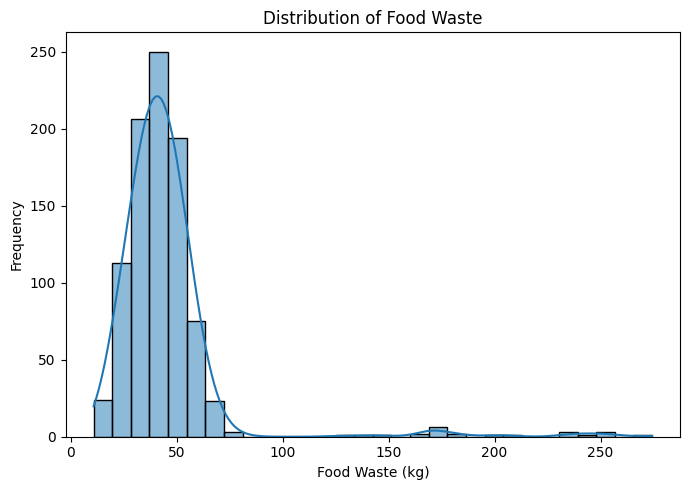

In [97]:
# Distribution of food waste
plt.figure(figsize=(7, 5))
sns.histplot(data=data, x="food_waste_kg", bins=30, kde=True)
plt.title("Distribution of Food Waste")
plt.xlabel("Food Waste (kg)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

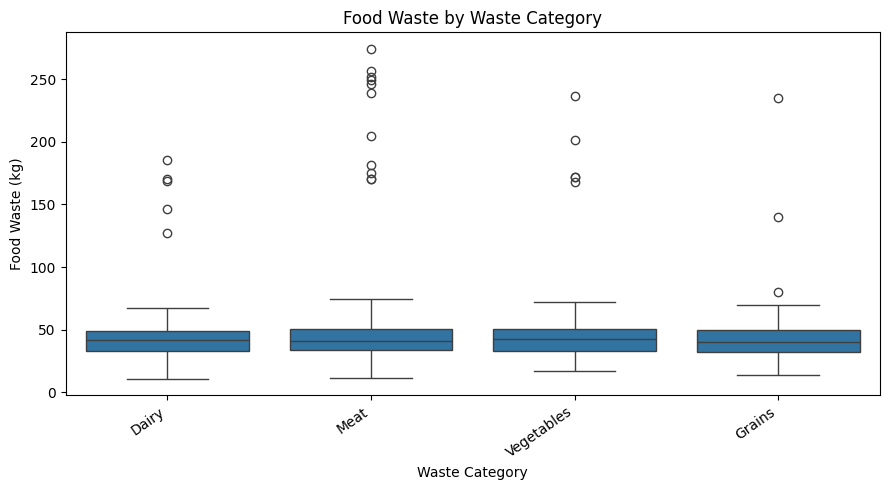

In [98]:
# Food waste by waste category
plt.figure(figsize=(9, 5))
sns.boxplot(data=data, x="waste_category", y="food_waste_kg")
plt.title("Food Waste by Waste Category")
plt.xlabel("Waste Category")
plt.ylabel("Food Waste (kg)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

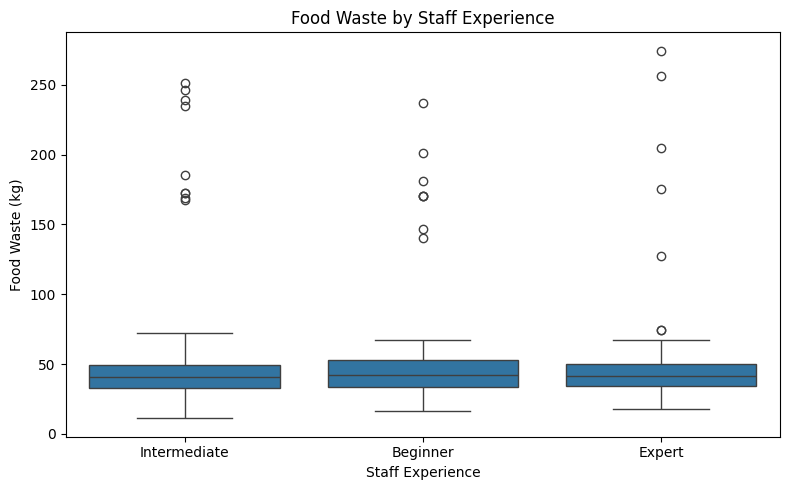

In [99]:
# Food waste by staff experience
plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x="staff_experience", y="food_waste_kg")
plt.title("Food Waste by Staff Experience")
plt.xlabel("Staff Experience")
plt.ylabel("Food Waste (kg)")
plt.tight_layout()
plt.show()

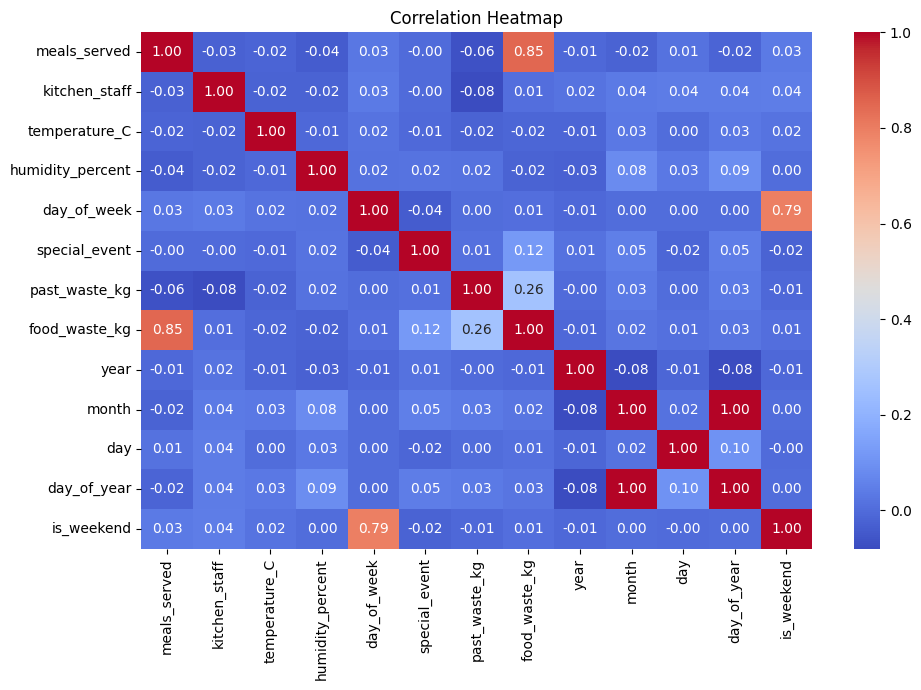

In [100]:
# Correlation heatmap for numerical variables
plt.figure(figsize=(10, 7))
sns.heatmap(data.select_dtypes(include=np.number).corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## 5. Prepare Features and Target

In [101]:
X = data.drop("food_waste_kg", axis=1)
y = data["food_waste_kg"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget summary:")
print(y.describe())

Features shape: (911, 14)
Target shape: (911,)

Target summary:
count    911.000000
mean      44.842691
std       27.934366
min       10.819048
25%       32.887912
50%       41.146930
75%       50.046681
max      274.328783
Name: food_waste_kg, dtype: float64


In [102]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (728, 14)
X_test: (183, 14)
y_train: (728,)
y_test: (183,)


In [103]:
# Preprocess numerical and categorical columns
numerical_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()

numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

print("Preprocessor created successfully.")

Preprocessor created successfully.


## 6. Linear Regression Model

In [104]:
import pandas as pd
import numpy as np

def fix_missing_values(df):
    df = df.copy()

    for col in df.columns:
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = pd.to_numeric(
                df[col], errors="coerce"
            ).astype(float)
        else:
            df[col] = df[col].astype(object)
            df[col] = df[col].where(df[col].notna(), np.nan)

    return df

X_train = fix_missing_values(X_train)
X_test = fix_missing_values(X_test)

print("Missing values fixed!")
print(X_train.dtypes)

Missing values fixed!
meals_served        float64
kitchen_staff       float64
temperature_C       float64
humidity_percent    float64
day_of_week         float64
special_event       float64
past_waste_kg       float64
staff_experience     object
waste_category       object
year                float64
month               float64
day                 float64
day_of_year         float64
is_weekend          float64
dtype: object


In [105]:
lr_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

lr_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [106]:
y_pred_lr = lr_model.predict(X_test)

mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression MAE:", round(mae_lr, 3))
print("Linear Regression RMSE:", round(rmse_lr, 3))
print("Linear Regression R2:", round(r2_lr, 3))

Linear Regression MAE: 5.691
Linear Regression RMSE: 11.474
Linear Regression R2: 0.743


## 7. Decision Tree Regressor

In [107]:
dt_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(max_depth=8, random_state=42))
])

dt_model.fit(X_train, y_train)
print("Decision Tree Regressor trained successfully!")

Decision Tree Regressor trained successfully!


In [108]:
y_pred_dt = dt_model.predict(X_test)

mae_dt = mean_absolute_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mean_squared_error(y_test, y_pred_dt))
r2_dt = r2_score(y_test, y_pred_dt)

print("Decision Tree MAE:", round(mae_dt, 3))
print("Decision Tree RMSE:", round(rmse_dt, 3))
print("Decision Tree R2:", round(r2_dt, 3))

Decision Tree MAE: 5.814
Decision Tree RMSE: 10.382
Decision Tree R2: 0.79


## 8. Random Forest Regressor

In [110]:
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300, max_depth=None, min_samples_leaf=2,
        random_state=42, n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)
print("Random Forest Regressor trained successfully!")

Random Forest Regressor trained successfully!


In [111]:

from sklearn.model_selection import cross_validate
import numpy as np

# 5-Fold Cross-Validation for Random Forest
cv_results = cross_validate(
    rf_model,
    X_train,
    y_train,
    cv=5,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    n_jobs=-1
)

mae_scores = -cv_results["test_MAE"]
rmse_scores = -cv_results["test_RMSE"]
r2_scores = cv_results["test_R2"]

print("Random Forest: 5-Fold Cross-Validation")
print(f"Mean MAE:  {mae_scores.mean():.3f} kg")
print(f"Mean RMSE: {rmse_scores.mean():.3f} kg")
print(f"Mean R2:   {r2_scores.mean():.3f}")
print(f"R2 Std:    {r2_scores.std():.3f}")


Random Forest: 5-Fold Cross-Validation
Mean MAE:  5.200 kg
Mean RMSE: 8.733 kg
Mean R2:   0.891
R2 Std:    0.055


In [112]:
y_pred_rf = rf_model.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest MAE:", round(mae_rf, 3))
print("Random Forest RMSE:", round(rmse_rf, 3))
print("Random Forest R2:", round(r2_rf, 3))

Random Forest MAE: 4.694
Random Forest RMSE: 6.928
Random Forest R2: 0.906


## 9. Compare the Models

In [113]:
model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree", "Random Forest"],
    "MAE (kg)": [mae_lr, mae_dt, mae_rf],
    "RMSE (kg)": [rmse_lr, rmse_dt, rmse_rf],
    "R2": [r2_lr, r2_dt, r2_rf]
})

display(model_comparison.sort_values("RMSE (kg)").reset_index(drop=True))

,Model,MAE (kg),RMSE (kg),R2
0,Random Forest,4.694098,6.928166,0.906318
1,Decision Tree,5.814349,10.381921,0.789635
2,Linear Regression,5.690890,11.474162,0.743043


## 10. Actual vs Predicted Plot

Best model by lowest RMSE: Random Forest


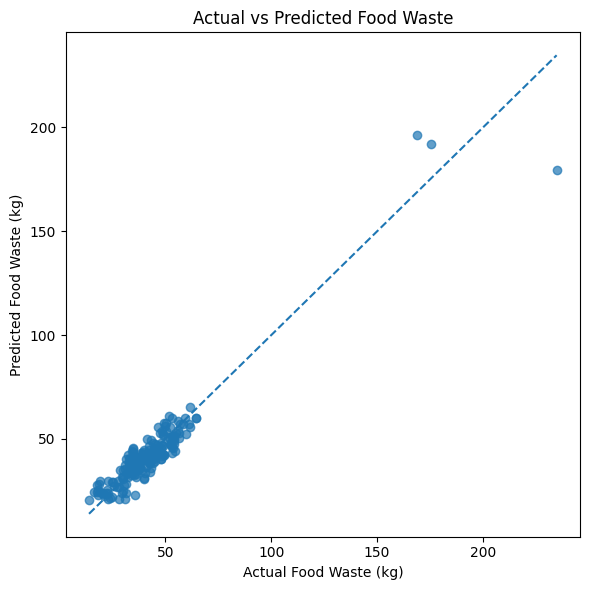

In [123]:
best_name = model_comparison.sort_values("RMSE (kg)").iloc[0]["Model"]
best_model = {
    "Linear Regression": lr_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model
}[best_name]
best_predictions = best_model.predict(X_test)

print("Best model by lowest RMSE:", best_name)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_predictions, alpha=0.7)
low = min(y_test.min(), best_predictions.min())
high = max(y_test.max(), best_predictions.max())
plt.plot([low, high], [low, high], "--")
plt.xlabel("Actual Food Waste (kg)")
plt.ylabel("Predicted Food Waste (kg)")
plt.title("Actual vs Predicted Food Waste")
plt.tight_layout()
plt.show()

## 11. Feature Importance (Random Forest)

In [115]:
# Feature importance is available for the Random Forest model
fitted_preprocessor = rf_model.named_steps["preprocessor"]
feature_names = fitted_preprocessor.get_feature_names_out()
importance = rf_model.named_steps["model"].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values("Importance", ascending=False)

display(feature_importance.head(15))

,Feature,Importance
0,num__meals_served,0.820696
6,num__past_waste_kg,0.097057
2,num__temperature_C,0.019987
1,num__kitchen_staff,0.015121
3,num__humidity_percent,0.014898
5,num__special_event,0.008785
17,cat__waste_category_Meat,0.005784
10,num__day_of_year,0.003981
9,num__day,0.003724
4,num__day_of_week,0.002586


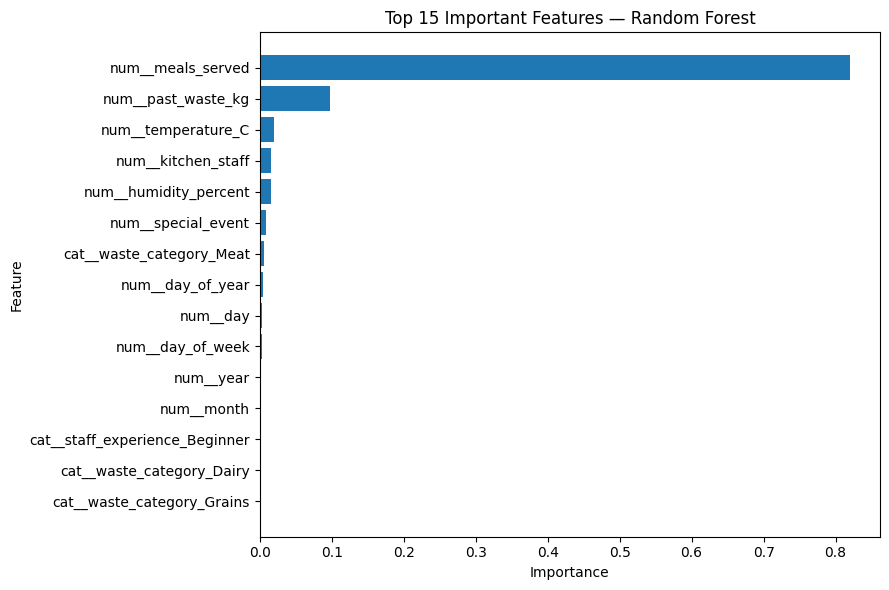

In [116]:
plt.figure(figsize=(9, 6))
top_features = feature_importance.head(15).sort_values("Importance")
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 15 Important Features — Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 12. Save the Best Model

In [117]:
joblib.dump(best_model, "food_waste_prediction_model.pkl")
print("Saved model: food_waste_prediction_model.pkl")

Saved model: food_waste_prediction_model.pkl


In [118]:
from google.colab import files
files.download("food_waste_prediction_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Example Prediction

In [119]:
sample = X_test.iloc[[0]]
actual_value = y_test.iloc[0]
predicted_value = best_model.predict(sample)[0]

print("Actual food waste (kg):", round(float(actual_value), 2))
print("Predicted food waste (kg):", round(float(predicted_value), 2))
display(sample)

Actual food waste (kg): 34.49
Predicted food waste (kg): 45.5


,meals_served,kitchen_staff,temperature_C,humidity_percent,day_of_week,special_event,past_waste_kg,staff_experience,waste_category,year,month,day,day_of_year,is_weekend
704,147.0,18.0,15.976383,63.124162,4.0,0.0,41.924846,Intermediate,Meat,2023.0,5.0,12.0,132.0,0.0


## Conclusion
This notebook compares three regression models for predicting food waste in kilograms. Run all cells and use the measured MAE, RMSE, and R² values to report performance. The model's predictions are estimates and should be validated before real-world use.